<a href="https://colab.research.google.com/github/vaishnavidangi704-commits/CSL701-11_Machine-Learning-Lab/blob/main/Experiments%20and%20Mini-Project/ML_Experiment_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Student Name : Vaishnavi Suryakant Dangi

Batch :CS-1


Roll Number :CS-11



### **Aim**

To implement graph-based clustering using Minimum Spanning Tree (MST) on the Breast Cancer Wisconsin (Diagnostic) dataset in Python and visualize the resulting clusters.

## Objectives

1. To understand the concept of graph-based clustering and Minimum Spanning Trees (MST).
2. To load and preprocess the Breast Cancer Wisconsin dataset (scaling features and handling metadata).
3. To construct a distance graph from tumor feature representations using Euclidean distance.
4. To compute the Minimum Spanning Tree using Prim's or Kruskal's algorithm (or via scipy/networkx).
5. To form $K=2$ clusters (Malignant vs. Benign) by removing the single ($K - 1$) largest edge weight from the MST.
6. To evaluate the performance of the MST-based clustering model using evaluation metrics.

# Relevant Theory

###Graph-Based Clustering & Minimum Spanning Tree (MST)
Graph-based clustering represents data points as nodes in a graph, with edges representing relationships or distance metrics between individual samples.
* **Complete Graph Construction**: Given a dataset $X = \{x_1, x_2, \dots, x_n\}$,
each tissue sample is treated as a vertex. An edge weight $w(i, j)$ corresponds to the distance between sample $i$ and sample $j$ (typically Euclidean distance on scaled features):$$w(i, j) = \Vert{}x_i - x_j\Vert{}_2$$
* **Minimum Spanning Tree (MST)**: An MST is a subset of edges connecting all vertices in the graph without forming any cycles, while minimizing the total edge weight sum.
* **MST-Based Clustering Method**:
  1. Construct a fully connected graph with pairwise edge weights across standardized features.
  2. Compute the Minimum Spanning Tree (MST).
  3. To partition the data into $K$ distinct clusters (such as Malignant and Benign groups), identify and remove the $K - 1$ largest (most expensive) edges from the MST.4. The resulting disconnected subgraphs represent the separate data clusters.
### Dataset Information
Get the Breast Cancer Wisconsin (Diagnostic) dataset from Kaggle or via scikit-learn (load_breast_cancer).
The dataset contains key cell nuclei features computed from digitized images of fine needle aspirates (FNA) of breast masses:
  * Total Instances: 569 samples
  * Target Classes: Malignant (M) and Benign (B)* Feature Attributes: 30 numerical features (e.g., mean radius, mean texture, mean perimeter, mean area, mean smoothness)

For 2D visualization, two key features (such as mean radius and mean texture) will be selected.

# Task 1: Import Libraries and Load Dataset

* Import required libraries (numpy, pandas, matplotlib, scipy, networkx, sklearn).

* Load the Breast Cancer dataset using below link from Kaggle.

  https://www.kaggle.com/datasets/utkarshx27/breast-cancer-wisconsin-diagnostic-dataset

---

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

from scipy.spatial.distance import pdist, squareform
from scipy.sparse.csgraph import minimum_spanning_tree, connected_components
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score

# Load dataset
data = load_breast_cancer()

df = pd.DataFrame(data.data, columns=data.feature_names)
df['diagnosis'] = np.where(data.target == 0, 'M', 'B')

print("Dataset Loaded Successfully")
print(df.head())
print("\nDataset Shape:", df.shape)

Dataset Loaded Successfully
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  

# Task 2: Explore the Dataset

* Display missing value checks, summary statistics, and feature dimensions.

* Check the diagnosis class distribution (Malignant vs. Benign).

Dataset Shape: (569, 31)

Missing Values:
mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
diagnosis                  0
dtype: int64

Summary Statistics:
       mean radius  mean 

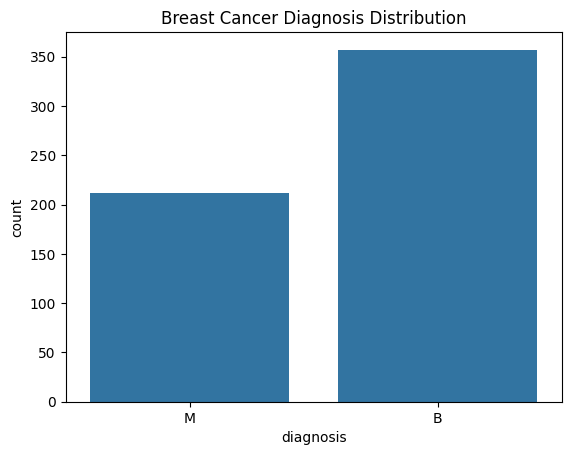

In [2]:
# Display dataset dimensions
print("Dataset Shape:", df.shape)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Summary statistics
print("\nSummary Statistics:")
print(df.describe())

# Diagnosis distribution
print("\nDiagnosis Distribution:")
print(df['diagnosis'].value_counts())

# Visualize diagnosis distribution
sns.countplot(data=df, x='diagnosis')
plt.title("Breast Cancer Diagnosis Distribution")
plt.show()

# Task 3: Preprocess and Scale Features

* Select numerical features and drop non-informative identifiers (such as id).

* Apply StandardScaler to normalize feature magnitudes prior to graph distance calculation.

In [3]:
# Separate features and target
X = df.drop('diagnosis', axis=1)
y = df['diagnosis']

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled Feature Shape:", X_scaled.shape)
print("\nFirst Five Rows of Scaled Data:")
print(X_scaled[:5])

Scaled Feature Shape: (569, 30)

First Five Rows of Scaled Data:
[[ 1.09706398e+00 -2.07333501e+00  1.26993369e+00  9.84374905e-01
   1.56846633e+00  3.28351467e+00  2.65287398e+00  2.53247522e+00
   2.21751501e+00  2.25574689e+00  2.48973393e+00 -5.65265059e-01
   2.83303087e+00  2.48757756e+00 -2.14001647e-01  1.31686157e+00
   7.24026158e-01  6.60819941e-01  1.14875667e+00  9.07083081e-01
   1.88668963e+00 -1.35929347e+00  2.30360062e+00  2.00123749e+00
   1.30768627e+00  2.61666502e+00  2.10952635e+00  2.29607613e+00
   2.75062224e+00  1.93701461e+00]
 [ 1.82982061e+00 -3.53632408e-01  1.68595471e+00  1.90870825e+00
  -8.26962447e-01 -4.87071673e-01 -2.38458552e-02  5.48144156e-01
   1.39236330e-03 -8.68652457e-01  4.99254601e-01 -8.76243603e-01
   2.63326966e-01  7.42401948e-01 -6.05350847e-01 -6.92926270e-01
  -4.40780058e-01  2.60162067e-01 -8.05450380e-01 -9.94437403e-02
   1.80592744e+00 -3.69203222e-01  1.53512599e+00  1.89048899e+00
  -3.75611957e-01 -4.30444219e-01 -1.46748

# Task 4: Construct Pairwise Distance Matrix & Graph

* Compute pairwise Euclidean distance matrix across all scaled samples using scipy.spatial.distance.pdist or cdist.

* Represent the dataset as a weighted complete graph.

In [4]:
# Calculate pairwise Euclidean distances
distance_vector = pdist(X_scaled, metric='euclidean')
distance_matrix = squareform(distance_vector)

print("Distance Matrix Shape:", distance_matrix.shape)
print("\nFirst 5x5 Distance Matrix:")
print(distance_matrix[:5, :5])

# Construct weighted complete graph
G = nx.Graph()

n_samples = X_scaled.shape[0]
G.add_nodes_from(range(n_samples))

for i in range(n_samples):
    for j in range(i + 1, n_samples):
        G.add_edge(i, j, weight=distance_matrix[i, j])

print("\nNumber of Nodes:", G.number_of_nodes())
print("Number of Edges:", G.number_of_edges())

Distance Matrix Shape: (569, 569)

First 5x5 Distance Matrix:
[[ 0.         10.31849715  6.77763352 10.47267382  8.67103637]
 [10.31849715  0.          5.0320153  16.25073886  4.37888839]
 [ 6.77763352  5.0320153   0.         12.84472056  4.46222854]
 [10.47267382 16.25073886 12.84472056  0.         15.37530011]
 [ 8.67103637  4.37888839  4.46222854 15.37530011  0.        ]]

Number of Nodes: 569
Number of Edges: 161596


# Task 5: Compute the Minimum Spanning Tree (MST)

* Compute the MST using scipy.sparse.csgraph.minimum_spanning_tree or networkx.minimum_spanning_tree.

* Extract the resulting graph connections and weights.

Minimum Spanning Tree Generated Successfully
Number of Nodes: 569
Number of Edges: 568

First 10 MST Edges:
0 77 4.8299
1 365 2.2871
2 535 2.4515
2 45 2.6763
2 77 3.7056
3 190 7.871
4 498 2.8827
5 47 2.5029
5 8 2.6951
5 105 2.7035


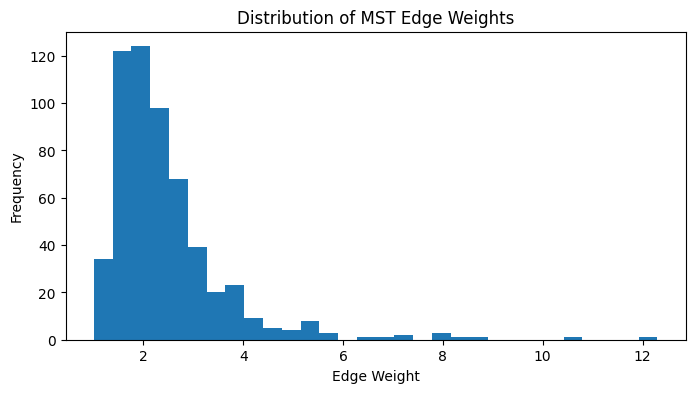

In [5]:
# Compute MST using NetworkX
mst = nx.minimum_spanning_tree(G, weight='weight')

print("Minimum Spanning Tree Generated Successfully")
print("Number of Nodes:", mst.number_of_nodes())
print("Number of Edges:", mst.number_of_edges())

# Display first 10 MST edges and their weights
print("\nFirst 10 MST Edges:")
for u, v, attributes in list(mst.edges(data=True))[:10]:
    print(u, v, round(attributes['weight'], 4))

# Visualize MST edge weights
edge_weights = [attributes['weight'] for _, _, attributes in mst.edges(data=True)]

plt.figure(figsize=(8, 4))
plt.hist(edge_weights, bins=30)
plt.title("Distribution of MST Edge Weights")
plt.xlabel("Edge Weight")
plt.ylabel("Frequency")
plt.show()

# Task 6: Implement Graph-Based Clustering ($K=2$)

* Sort the edges of the MST in descending order by edge weight.
* Remove the largest $K - 1$ edge (1 largest edge for 2 clusters) to split the MST into 2 connected components.
* Assign final cluster labels based on the resulting component indices.


In [6]:
# Copy MST to preserve the original
cluster_graph = mst.copy()

# Sort MST edges in descending order of weight
sorted_edges = sorted(
    cluster_graph.edges(data=True),
    key=lambda edge: edge[2]['weight'],
    reverse=True
)

# Remove the largest edge to create 2 clusters
largest_edge = sorted_edges[0]
cluster_graph.remove_edge(largest_edge[0], largest_edge[1])

print("Removed Edge:", largest_edge[0], largest_edge[1])
print("Removed Edge Weight:", round(largest_edge[2]['weight'], 4))

# Assign cluster labels using connected components
components = list(nx.connected_components(cluster_graph))

cluster_labels = np.zeros(n_samples, dtype=int)

for cluster_id, nodes in enumerate(components):
    for node in nodes:
        cluster_labels[node] = cluster_id

df['cluster'] = cluster_labels

print("\nNumber of Clusters:", len(components))
print("\nCluster Distribution:")
print(df['cluster'].value_counts())

print("\nFirst 10 Cluster Assignments:")
print(df[['diagnosis', 'cluster']].head(10))

Removed Edge: 461 503
Removed Edge Weight: 12.2999

Number of Clusters: 2

Cluster Distribution:
cluster
0    567
1      2
Name: count, dtype: int64

First 10 Cluster Assignments:
  diagnosis  cluster
0         M        0
1         M        0
2         M        0
3         M        0
4         M        0
5         M        0
6         M        0
7         M        0
8         M        0
9         M        0


# Task 7: valuate MST Clustering Performance

Evaluate cluster assignment against ground truth labels using:

  *  Silhouette Score

  *  Adjusted Rand Index (ARI)

  *  Normalized Mutual Information (NMI)

In [7]:
# Ground truth labels
true_labels = np.where(y == 'M', 1, 0)

# Calculate evaluation metrics
sil_score = silhouette_score(X_scaled, cluster_labels)
ari_score = adjusted_rand_score(true_labels, cluster_labels)
nmi_score = normalized_mutual_info_score(true_labels, cluster_labels)

print("MST Clustering Evaluation")
print("-------------------------")
print("Silhouette Score:", round(sil_score, 4))
print("Adjusted Rand Index (ARI):", round(ari_score, 4))
print("Normalized Mutual Information (NMI):", round(nmi_score, 4))

MST Clustering Evaluation
-------------------------
Silhouette Score: 0.6607
Adjusted Rand Index (ARI): 0.0048
Normalized Mutual Information (NMI): 0.0102


# Task 8: Visualize MST and Graph-Based Clusters

* Select two representative features (e.g., mean radius vs. mean texture) for 2D plotting.
 * Plot 1: Unclustered standardized data points.
* Plot 2: Minimum Spanning Tree (MST) edge connections overlaid on the data.
* Plot 3: Final clusters formed after cutting the $K - 1$ largest edge(s).

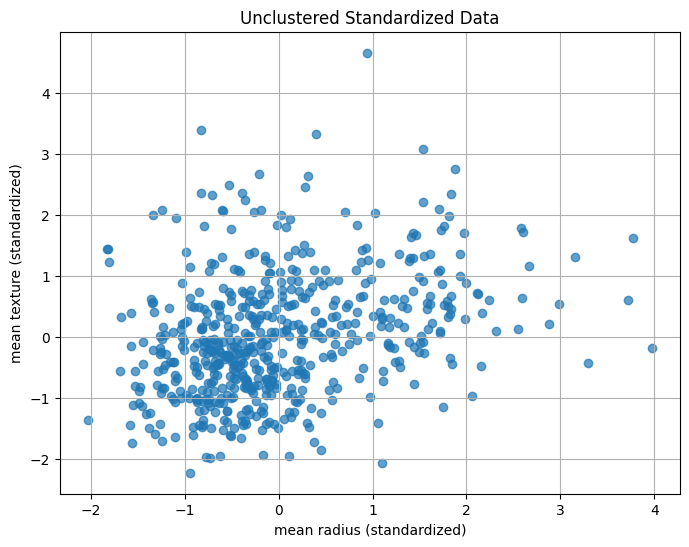

In [8]:
# Select two features for visualization
feature_x = 'mean radius'
feature_y = 'mean texture'

X_2d = X_scaled[:, [0, 1]]

plt.figure(figsize=(8, 6))
plt.scatter(X_2d[:, 0], X_2d[:, 1], alpha=0.7)
plt.title("Unclustered Standardized Data")
plt.xlabel(feature_x + " (standardized)")
plt.ylabel(feature_y + " (standardized)")
plt.grid(True)
plt.show()

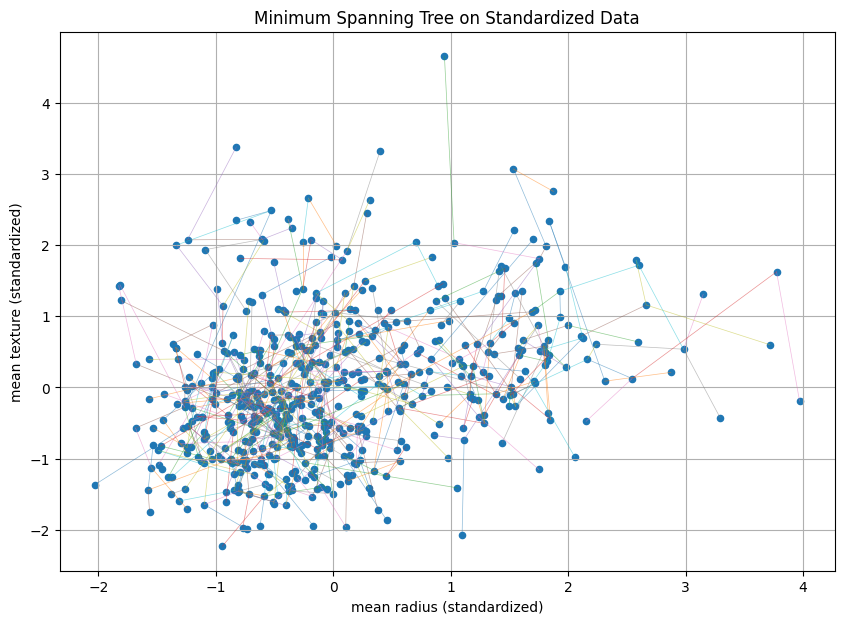

In [9]:
plt.figure(figsize=(10, 7))

# Plot data points
plt.scatter(X_2d[:, 0], X_2d[:, 1], s=20)

# Draw MST edges
for u, v in mst.edges():
    plt.plot(
        [X_2d[u, 0], X_2d[v, 0]],
        [X_2d[u, 1], X_2d[v, 1]],
        linewidth=0.5,
        alpha=0.5
    )

plt.title("Minimum Spanning Tree on Standardized Data")
plt.xlabel(feature_x + " (standardized)")
plt.ylabel(feature_y + " (standardized)")
plt.grid(True)
plt.show()

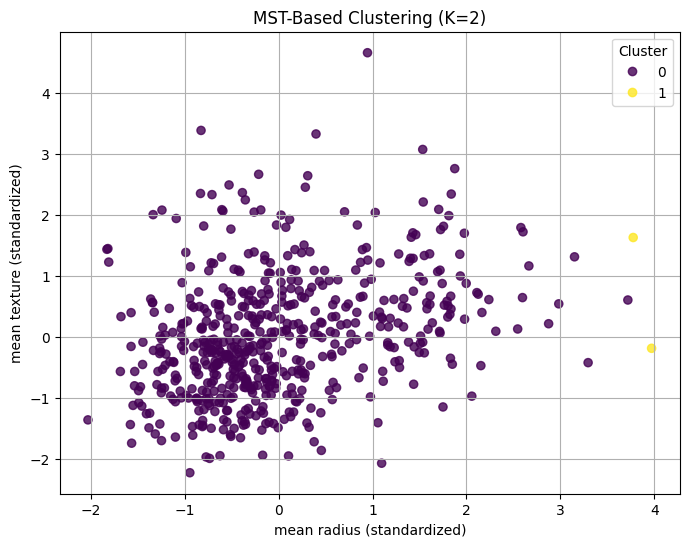

In [10]:
plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    X_2d[:, 0],
    X_2d[:, 1],
    c=cluster_labels,
    cmap='viridis',
    s=35,
    alpha=0.8
)

plt.title("MST-Based Clustering (K=2)")
plt.xlabel(feature_x + " (standardized)")
plt.ylabel(feature_y + " (standardized)")
plt.legend(*scatter.legend_elements(), title="Cluster")
plt.grid(True)
plt.show()

Actual Diagnosis vs MST Cluster:
MST Cluster         0  1
Actual Diagnosis        
B                 357  0
M                 210  2


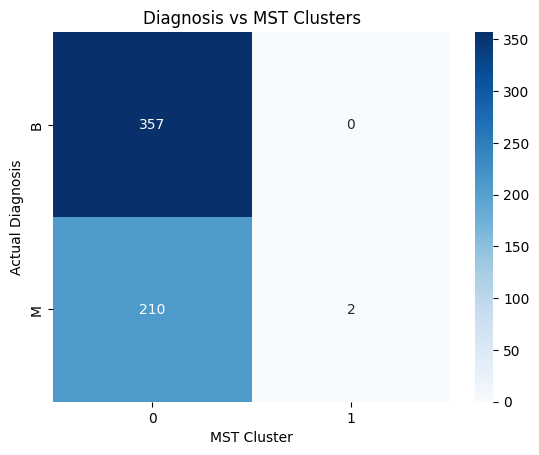

In [11]:
comparison = pd.crosstab(
    df['diagnosis'],
    df['cluster'],
    rownames=['Actual Diagnosis'],
    colnames=['MST Cluster']
)

print("Actual Diagnosis vs MST Cluster:")
print(comparison)

sns.heatmap(comparison, annot=True, fmt='d', cmap='Blues')
plt.title("Diagnosis vs MST Clusters")
plt.show()

# Conclusion

The experiment successfully demonstrated the implementation of Graph-Based Clustering using a Minimum Spanning Tree (MST) on the Breast Cancer Wisconsin (Diagnostic) dataset. The dataset was preprocessed, cleaned, and standardized before computing pairwise distances. The MST was generated, and by removing the largest edge(s), clusters representing tumor categories were obtained, evaluated using clustering metrics, and visualized.